# Workflow study: DMRG → MPS-to-circuit → filter on the 1D $J_1$-$J_2$ chain

**Model.** Open chain $H = J_1\sum_i \mathbf S_i\cdot\mathbf S_{i+1} + J_2\sum_i \mathbf S_i\cdot\mathbf S_{i+2}$, $J_2 = 0.2411$, **no dimerisation**: the gap and the
spectral width are whatever the chain has at each $N$, so $\eta(N) = \Delta/W$ shrinks with $N$.

**Pipeline per N.** DMRG spectral estimates ($E_0$; $E_1$ from DMRG with a penalty that pushes the ground-state sector up; $E_{\max}$ from DMRG on $-H$) and DMRG ground state → 1-layer MPS-to-circuit ([qiskit-community/mps-to-circuit](https://github.com/qiskit-community/mps-to-circuit)) → trial state with its natural overlap $\gamma_0(N)$ → filter → post-selected ground state with $1-F\le\epsilon$.

**Methods** (all apply the same filter polynomial $F = \prod_{k<K}\cos(2^k\tau H_s)^r$, $H_s=(H-E_0)/W$, $\tau=\pi/(1+\eta)$, built from second-order Strang steps):

| method | qubits | how success is reached |
|---|---|---|
| SBC (RUS) | $N+1$ | one ancilla, measured and reset after each pulse; repeat until success, $1/p$ attempts |
| SBC + AA | $N+Kr$ | one ancilla per pulse (no mid-circuit measurement), $k\approx\pi/4\sqrt p$ Grover rounds |
| QETU (RUS) | $N+1$ | one ancilla, $d=r(2^K-1)$ controlled steps interleaved with $d+1$ ancilla $R_x(\phi_j)$ |
| QETU + AA | $N+1$ | QETU inside AA; $R_{good}$ is a single-qubit $Z$ |

**Simulation.** Exact in the $S^z=0$ sector: the Strang step $S$ is diagonalised once per $(N, n)$, so $p$ and $1-F$ of the Trotterised circuit are exact for every $(K, r)$. QETU on the same Strang step applies the same polynomial to the same eigenphases, so its $p$ and $1-F$ equal SBC's (checked gate by gate in `filter_walkthrough.ipynb`); only the gate counts differ.

**Costs.** CNOTs and non-Clifford $R_z$ (angle not a multiple of $\pi/2$) after compiling to {CX, Rz, SX, X}. Per method, $(K, r, n)$ is chosen to minimise the CNOTs per success **including trial preparation**, with $\tau$ and $H_s$ set from the DMRG estimates (fidelity is measured against the exact ground state), with $1-F\le\epsilon$ required at $n$ and at the next finer $n$ (no lucky Trotter cancellations). AA assumes $p$ is known.

In [1]:
# ---- parameters
NS       = [6, 8, 10, 12, 14, 16]       # chain lengths (N = 16 adds ~10 min: Strang spectra in a 12870-dim sector)
J1, J2   = 1.0, 0.2411
EPS      = 1e-2                         # target infidelity of the post-selected state
N_GRID   = [1, 2, 3, 4, 6, 8, 12, 16]   # Strang steps per τ tried
K_MAX, R_MAX = 16, 12
DMRG_BONDS = [16, 32, 64, 128]

import os, sys, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, os.path.abspath("."))                       # run from ORNL/
from ornl import Chain
from ornl.trotter import step_spectrum
from ornl.prep import truncate_bond2
import quimb.operator as qop, quimb.tensor as qtn
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from mps_to_circuit import mps_to_circuit                         # pip install --ignore-requires-python mps-to-circuit
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

## 1. Gate-count model and its check against real Qiskit circuits

Controlled bond $e^{-i\phi(XX+YY+ZZ)Z_a}$: Clifford Bell change + 4-CNOT parity network = **6 CNOT, 3 non-Clifford Rz**. A controlled run of $m$ merged Strang steps has $(2B-2)m+1$ bond blocks ($B=2N-3$ bonds) plus one ancilla Rz for the $-E_0/W$ part.
SBC merges the steps inside each pulse; QETU cannot merge across its $R_x(\phi_j)$, so each of its $d$ calls is a separate run of $n$ steps. Multi-controlled Z for the AA reflections is counted from Qiskit's synthesis. The model is a slight upper bound: Qiskit's transpiler cancels about 6% of the CNOTs between neighbouring blocks (see the check below).

In [2]:
CLIFF = lambda x: abs(x / (np.pi / 2) - round(x / (np.pi / 2))) < 1e-9

def counts(qc):
    t = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
    rz = [float(g.operation.params[0]) for g in t.data if g.operation.name == "rz"]
    return np.array([t.count_ops().get("cx", 0), sum(not CLIFF(x) for x in rz)])

def blocks(N, m):                     # bond blocks in m merged Strang steps
    return (2 * (2 * N - 3) - 2) * m + 1

def sbc_attempt(N, K, r, n):          # (CNOT, non-Clifford Rz) of one SBC attempt (K r pulses)
    b = sum(blocks(N, n * 2 ** k) for k in range(K)) * r
    return np.array([6 * b, 3 * b + K * r])

def qetu_attempt(N, K, r, n):         # d controlled n-step runs + (d + 1) ancilla Rx
    d = r * (2 ** K - 1)
    return np.array([6 * d * blocks(N, n), d * (3 * blocks(N, n) + 1) + d + 1])

_mcz = {}
def mcz(nq):                          # sign flip of |0...0> on nq qubits
    if nq not in _mcz:
        qc = QuantumCircuit(nq); qc.x(range(nq))
        if nq == 1: qc.z(0)
        else: qc.h(nq - 1); qc.mcx(list(range(nq - 1)), nq - 1); qc.h(nq - 1)
        qc.x(range(nq)); _mcz[nq] = counts(qc)
    return _mcz[nq]

# ---- check the model on real circuits (N = 6, K = 2, r = 2, n = 2)
def bond_block(qc, i, j, a, phi):
    qc.cx(i, j); qc.h(i)
    qc.cx(i, a); qc.rz(2 * phi, a); qc.cx(j, a); qc.rz(-2 * phi, a); qc.cx(i, a); qc.rz(2 * phi, a); qc.cx(j, a)
    qc.h(i); qc.cx(i, j)
def ctrl_run(qc, ch, a, t, steps):
    one = list(range(len(ch.bonds))) + list(range(len(ch.bonds)))[::-1]; seq = []
    for b in one * steps:
        if seq and seq[-1][0] == b: seq[-1][1] += 1
        else: seq.append([b, 1])
    for b, w in seq:
        i, j, J = ch.bonds[b]; bond_block(qc, i, j, a, w * (t / steps / 2) * J / (4 * ch.W))
    qc.rz(-2 * t * ch.E0 / ch.W, a)
ch6, K_, r_, n_ = Chain(6, 0.0, J1, J2), 2, 2, 2
tau6 = np.pi / (1 + ch6.gap_s)
sbc = QuantumCircuit(7)
for _ in range(r_):
    for k in range(K_):
        sbc.h(6); ctrl_run(sbc, ch6, 6, 2 ** k * tau6, 2 ** k * n_); sbc.h(6)
qetu = QuantumCircuit(7); rng = np.random.default_rng(1); qetu.rx(rng.normal(), 6)
for _ in range(r_ * (2 ** K_ - 1)):
    ctrl_run(qetu, ch6, 6, tau6, n_); qetu.rx(rng.normal(), 6)
print("                 model (CNOT, Rz)   Qiskit transpiled (CNOT, Rz)")
print(f"SBC  attempt     {tuple(sbc_attempt(6, K_, r_, n_))}        {tuple(counts(sbc))}")
print(f"QETU attempt     {tuple(qetu_attempt(6, K_, r_, n_))}        {tuple(counts(qetu))}")
print("MCZ (CNOT, Rz) by qubit count: " + ", ".join(f"{q}: {tuple(mcz(q))}" for q in (2, 5, 10, 20, 40)))

                 model (CNOT, Rz)   Qiskit transpiled (CNOT, Rz)
SBC  attempt     (np.int64(1176), np.int64(592))        (np.int64(1102), np.int64(592))
QETU attempt     (np.int64(1188), np.int64(607))        (np.int64(1110), np.int64(607))
MCZ (CNOT, Rz) by qubit count: 2: (np.int64(1), np.int64(0)), 5: (np.int64(36), np.int64(43)), 10: (np.int64(290), np.int64(303)), 20: (np.int64(1370), np.int64(1403)), 40: (np.int64(4746), np.int64(3998))


## 2. Per N: ED reference, DMRG, 1-layer MPS-to-circuit trial

ED in the $S^z=0$ sector gives the exact reference (used only to measure errors and fidelity). DMRG gives the spectral estimates that set the filter, and the MPS that is compiled to one layer of two-qubit gates; the prepared state's overlap with the exact ground state is $\gamma_0(N)$, its gate cost is the prep cost.

The package's `approximate` method compresses to bond dimension 2 with a plain SVD. At $\delta = 0$ the Schmidt spectrum has degenerate triplet multiplets, and the plain SVD keeps an arbitrary mix of them, so part of the state leaves $S^z=0$ (column `leak_pkg_default`: up to several percent, varying with N; `gamma0_pkg_default` is the overlap it reaches). The sector simulation below needs the trial inside $S^z=0$, so here the truncation to bond 2 is done block by block in $S^z$ (`ornl.prep.truncate_bond2`) and the package's `exact` method turns that bond-2 MPS into the one-layer circuit, which keeps the trial in $S^z=0$.

In [3]:
def dmrg(N, sign=1.0, penalty=None):
    bonds = [(i, i + 1, J1) for i in range(N - 1)] + [(i, i + 2, J2) for i in range(N - 2)]
    Jd = {(i, j): sign * J for i, j, J in bonds}
    b = qop.heisenberg_from_edges(list(Jd), j=lambda i, j: Jd[(i, j)] if (i, j) in Jd else Jd[(j, i)])
    if penalty:                       # penalty (S^z_tot - 1)^2: the S^z = 0 ground state is pushed up, the triplet is not
        for i in range(N):
            for j in range(N):
                if i != j:
                    b.add_term(penalty, ("sz", i), ("sz", j))
            b.add_term(-2 * penalty, ("sz", i))
    d = qtn.DMRG2(b.build_mpo(), bond_dims=DMRG_BONDS, cutoffs=1e-12); d.solve(tol=1e-10, verbosity=0, max_sweeps=40)
    E = float(np.real(d.energy)) + (penalty * (N / 4 + 1) if penalty else 0.0)   # constant part of the penalty
    return E, d.state

def dmrg_ground_state(N):
    return dmrg(N)

chains, prep = {}, []
for N in NS:
    t0 = time.time()
    ch = Chain(N, 0.0, J1, J2)
    E0_d, psi = dmrg_ground_state(N)
    q = sum((((ch.states >> (N - 1 - i)) & 1) << i) for i in range(N))   # sector basis state -> qiskit index
    # (a) package default: approximate method, 1 layer (its bond-2 compression ignores S^z)
    mps = psi.copy(); mps.permute_arrays("lrp")
    full_a = Statevector(mps_to_circuit(list(mps.arrays), method="approximate", shape="lrp", num_layers=1)).data
    va = full_a[q]
    # (b) used here: S^z-conserving truncation to bond 2 (ornl.prep), then the package's exact bond-2 -> circuit map
    B = truncate_bond2(psi.to_dense().ravel(), N); B[0] = B[0] / np.linalg.norm(B[0])
    qc = mps_to_circuit(B, method="exact", shape="lpr")
    v = Statevector(qc).data[q]
    leak = 1 - np.vdot(v, v).real
    ch.set_base(v, label="mps-to-circuit")
    # spectral estimates from DMRG set the filter (τ, H_s); the exact values are kept only to report the errors
    E1_d, Emax_d = dmrg(N, penalty=2.0)[0], -dmrg(N, sign=-1.0)[0]
    exact = (ch.E0, ch.E1, ch.Emax, ch.gap_s)
    ch.E0, ch.E1, ch.Emax = E0_d, E1_d, Emax_d
    ch.gap, ch.W = E1_d - E0_d, Emax_d - E0_d
    ch.gap_s = ch.gap / ch.W
    ch.prep = counts(qc)
    chains[N] = ch
    prep.append(dict(N=N, E0=ch.E0, dmrg_E0_err=abs(E0_d - exact[0]), dmrg_E1_err=abs(E1_d - exact[1]),
                     dmrg_Emax_err=abs(Emax_d - exact[2]), dmrg_eta_err=abs(ch.gap_s - exact[3]), gap=ch.gap, W=ch.W, eta=ch.gap_s,
                     gamma0=ch.gamma0, leak_out_of_Sz0=leak, prep_CNOT=ch.prep[0], prep_nonCliff_Rz=ch.prep[1],
                     gamma0_pkg_default=abs(np.vdot(ch.g0, va)) ** 2, leak_pkg_default=1 - np.vdot(va, va).real,
                     seconds=time.time() - t0))
prep = pd.DataFrame(prep).set_index("N")
display(prep.style.format({"E0": "{:.6f}", "dmrg_E0_err": "{:.1e}", "dmrg_E1_err": "{:.1e}", "dmrg_Emax_err": "{:.1e}", "dmrg_eta_err": "{:.1e}", "gap": "{:.4f}", "W": "{:.4f}", "eta": "{:.5f}",
                           "gamma0": "{:.4f}", "leak_out_of_Sz0": "{:.1e}", "gamma0_pkg_default": "{:.4f}",
                           "leak_pkg_default": "{:.3f}", "seconds": "{:.1f}"}))

,E0,dmrg_E0_err,dmrg_E1_err,dmrg_Emax_err,dmrg_eta_err,gap,W,eta,gamma0,leak_out_of_Sz0,prep_CNOT,prep_nonCliff_Rz,gamma0_pkg_default,leak_pkg_default,seconds
N,,,,,,,,,,,,,,,
6,-2.335347,2.2e-15,1.8e-15,6.7e-16,9.4e-16,0.4878,3.8264,0.12748,0.9489,-6.7e-16,13,49,0.9494,0.010,0.4
8,-3.135001,2.2e-15,3.1e-15,1.8e-15,2.4e-16,0.3859,5.2467,0.07355,0.9101,-1.1e-15,19,69,0.9111,0.001,0.2
10,-3.936128,2.8e-12,8.0e-12,8.0e-15,8.1e-13,0.3191,6.6683,0.04785,0.8654,-1.3e-15,21,80,0.8690,0.006,0.4
12,-4.738077,1.0e-11,5.4e-12,5.8e-15,5.5e-13,0.2720,8.0908,0.03362,0.8193,-1.3e-15,25,94,0.8252,0.001,1.7
14,-5.540531,2.3e-11,1.2e-11,3.2e-13,1.2e-12,0.2370,9.5138,0.02491,0.7726,-2.2e-15,29,110,0.7810,0.003,4.2
16,-6.343316,3.2e-11,2.7e-11,8.4e-12,3.4e-13,0.2100,10.9372,0.01920,0.7262,-1.8e-15,33,124,0.7373,0.057,7.7


## 3. Cheapest filter per method and N

For each $n$ the Strang step is diagonalised once; for every $(K, r)$ the filter acts as $\prod_k\cos(2^k n\varphi_j)^r$ on its eigenphases $\varphi_j$, giving $p$ and $1-F$ exactly. A choice counts only if $1-F\le\epsilon$ also holds at the next $n$ in the grid. $n$ is raised until a level brings no cheaper choice for any method.

In [4]:
METHODS = ["SBC", "SBC+AA", "QETU", "QETU+AA"]

def method_cost(N, K, r, n, p, prep_c, best_so_far):
    # cost per success of each method (trial prep inside every attempt); AA only where a Grover round helps
    s_att, q_att = sbc_attempt(N, K, r, n) + prep_c, qetu_attempt(N, K, r, n) + prep_c
    s_flt, q_flt = sbc_attempt(N, K, r, n), qetu_attempt(N, K, r, n)
    out = dict(SBC=dict(run=s_att, flt=s_flt, P=p, k=0, qubits=N + 1), QETU=dict(run=q_att, flt=q_flt, P=p, k=0, qubits=N + 1))
    th = np.arcsin(np.sqrt(p)); k = max(0, int(round(np.pi / (4 * th) - 0.5))); P = np.sin((2 * k + 1) * th) ** 2
    for name, att, flt, refl, nq in (("SBC+AA", s_att, s_flt, lambda: mcz(K * r) + mcz(N + K * r), N + K * r),
                                     ("QETU+AA", q_att, q_flt, lambda: mcz(1) + mcz(N + 1), N + 1)):
        plain = dict(out[name.split("+")[0]])
        if k >= 1 and (2 * k + 1) * float(att[0]) / P < min(best_so_far.get(name, np.inf), float(att[0]) / p):
            R = refl()
            out[name] = dict(run=(2 * k + 1) * att.astype(float) + k * R, flt=(2 * k + 1) * flt.astype(float) + k * R,
                             P=P, k=k, qubits=nq)
        else:
            out[name] = plain
    for v in out.values():
        v["tot"], v["filt"] = np.asarray(v["run"], float) / v["P"], np.asarray(v["flt"], float) / v["P"]
    return out

def scan(ch, n):
    phi, project = step_spectrum(ch, np.pi / (1 + ch.gap_s) / n)
    theta = n * phi
    c, u = project(ch.base), project(ch.g0)
    w = abs(c) ** 2; data = {}; Bk = np.ones_like(theta)
    for K in range(1, K_MAX + 1):
        Bk = Bk * np.cos(2.0 ** (K - 1) * theta); Br = np.ones_like(theta); ps, infs = [], []
        for _ in range(R_MAX):
            Br = Br * Bk
            p = (Br ** 2) @ w
            ps.append(p); infs.append(1 - abs((u * Br) @ c) ** 2 / max(p, 1e-300))
        data[K] = (np.array(ps), np.array(infs))
    return data

rows = []
for N in NS:
    ch, t0 = chains[N], time.time()
    levels, best = [], {}
    for i, n in enumerate(N_GRID):
        levels.append((n, scan(ch, n)))
        if i == 0:
            continue
        n_prev, d_prev = levels[i - 1]; d_chk = levels[i][1]
        improved = False
        for K in range(1, K_MAX + 1):
            ok = np.flatnonzero((d_prev[K][1] <= EPS) & (d_chk[K][1] <= EPS))
            if not len(ok):
                continue
            r = ok[0] + 1; p = d_prev[K][0][r - 1]
            if p < 1e-8:
                continue
            cur = {m: best[m]["tot"][0] for m in best}
            for name, x in method_cost(N, K, r, n_prev, p, ch.prep, cur).items():
                if name not in best or x["tot"][0] < best[name]["tot"][0]:
                    best[name] = dict(x, K=K, r=r, n=n_prev, p=p, infid=d_prev[K][1][r - 1]); improved = True
        if i >= 2 and not improved and len(best) == len(METHODS):
            break
    for name in METHODS:
        b = best[name]
        rows.append(dict(N=N, method=name, eta=ch.gap_s, gamma0=ch.gamma0, K=b["K"], r=b["r"], n=b["n"],
                         d=b["r"] * (2 ** b["K"] - 1), qubits=b["qubits"], AA_k=b["k"], p=b["p"], P_run=b["P"],
                         infid=b["infid"], CNOT_run=b["run"][0], Rz_run=b["run"][1],
                         CNOT_per_success=b["tot"][0], Rz_per_success=b["tot"][1],
                         filter_CNOT_per_success=b["filt"][0], filter_Rz_per_success=b["filt"][1]))
    print(f"N = {N}: done in {time.time() - t0:.0f} s (n up to {levels[-1][0]})")
res = pd.DataFrame(rows)
res.to_csv("results/workflow_study.csv", index=False); prep.to_csv("results/workflow_prep.csv")

N = 6: done in 0 s (n up to 3)
N = 8: done in 0 s (n up to 3)
N = 10: done in 0 s (n up to 4)


N = 12: done in 0 s (n up to 3)


N = 14: done in 12 s (n up to 3)


N = 16: done in 322 s (n up to 3)


## 4. Results

In [5]:
fmt = {c: "{:.4g}" for c in ["eta", "gamma0", "p", "P_run", "CNOT_run", "Rz_run", "CNOT_per_success", "Rz_per_success",
                              "filter_CNOT_per_success", "filter_Rz_per_success"]}
fmt["infid"] = "{:.2e}"
display(res.set_index(["N", "method"]).style.format(fmt))

print("\nCNOT per success (trial prep included)")
display(res.pivot(index="N", columns="method", values="CNOT_per_success")[METHODS].style.format("{:.4g}"))
print("non-Clifford Rz per success (trial prep included)")
display(res.pivot(index="N", columns="method", values="Rz_per_success")[METHODS].style.format("{:.4g}"))
print("qubits")
display(res.pivot(index="N", columns="method", values="qubits")[METHODS])

fits = []
for name in METHODS:
    s = res[res.method == name]
    for col in ("CNOT_per_success", "Rz_per_success", "filter_CNOT_per_success"):
        a, b = np.polyfit(np.log(s.N), np.log(s[col]), 1)
        fits.append(dict(method=name, quantity=col, exponent_in_N=a, prefactor=np.exp(b)))
print("power-law fits  cost ≈ C · N^α  over N =", NS)
display(pd.DataFrame(fits).pivot(index="method", columns="quantity", values="exponent_in_N").loc[METHODS].round(2))


CNOT per success (trial prep included)


method,SBC,SBC+AA,QETU,QETU+AA
N,,,,
6,329.1,329.1,333.7,333.7
8,985.9,985.9,999,999
10,3117,3117,3145,3145
12,4431,4431,4511,4511
14,1.123e+04,1.123e+04,1.14e+04,1.14e+04
16,1.382e+04,1.382e+04,1.4e+04,1.4e+04


non-Clifford Rz per success (trial prep included)


method,SBC,SBC+AA,QETU,QETU+AA
N,,,,
6,211.3,211.3,218.6,218.6
8,562,562,578.3,578.3
10,1642,1642,1669,1669
12,2319,2319,2392,2392
14,5749,5749,5902,5902
16,7067,7067,7229,7229


qubits


method,SBC,SBC+AA,QETU,QETU+AA
N,,,,
6,7,7,7,7
8,9,9,9,9
10,11,11,11,11
12,13,13,13,13
14,15,15,15,15
16,17,17,17,17


power-law fits  cost ≈ C · N^α  over N = [6, 8, 10, 12, 14, 16]


quantity,CNOT_per_success,Rz_per_success,filter_CNOT_per_success
method,,,
SBC,3.92,3.69,3.95
SBC+AA,3.92,3.69,3.95
QETU,3.92,3.68,3.95
QETU+AA,3.92,3.68,3.95


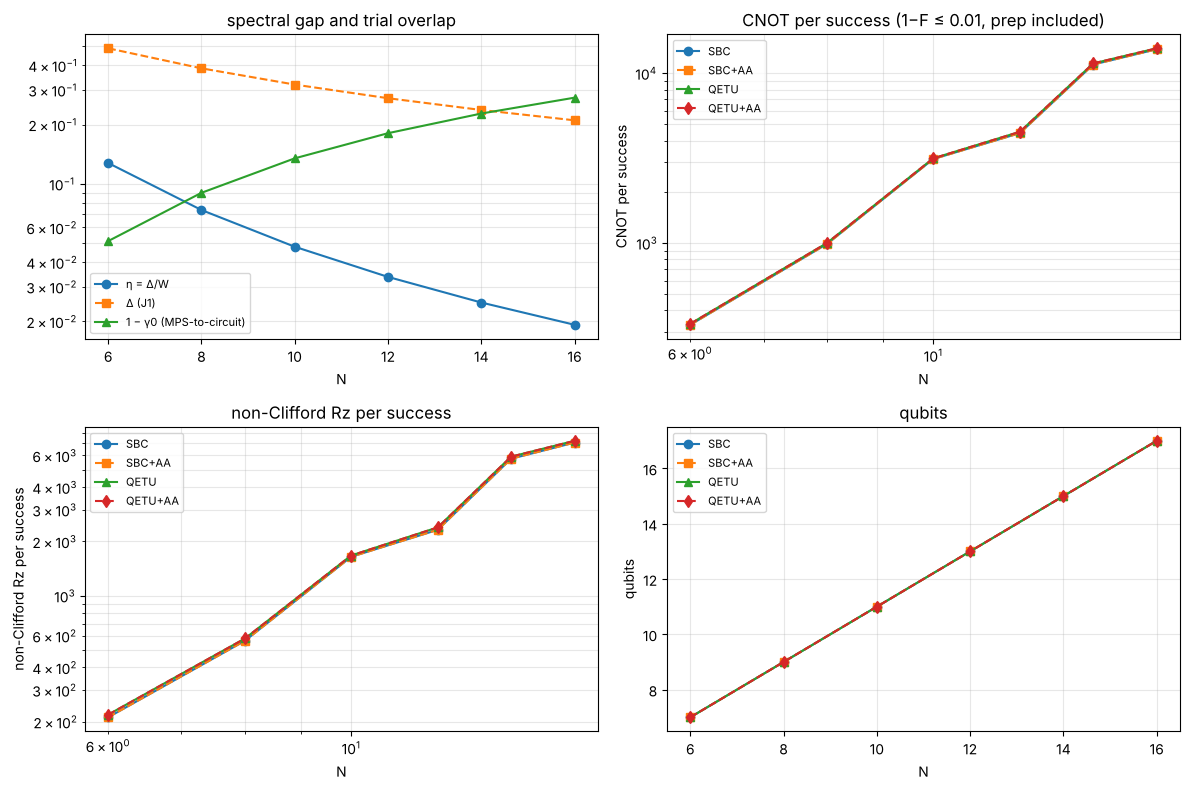

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].semilogy(prep.index, prep.eta, "o-", label="η = Δ/W")
ax[0, 0].semilogy(prep.index, prep.gap, "s--", label="Δ (J1)")
ax[0, 0].semilogy(prep.index, 1 - prep.gamma0, "^-", label="1 − γ0 (MPS-to-circuit)")
ax[0, 0].set(xlabel="N", title="spectral gap and trial overlap"); ax[0, 0].legend()
mk = dict(zip(METHODS, ["o-", "s--", "^-", "d--"]))
for name in METHODS:
    s = res[res.method == name]
    ax[0, 1].loglog(s.N, s.CNOT_per_success, mk[name], label=name)
    ax[1, 0].loglog(s.N, s.Rz_per_success, mk[name], label=name)
    ax[1, 1].plot(s.N, s.qubits, mk[name], label=name)
ax[0, 1].set(xlabel="N", ylabel="CNOT per success", title=f"CNOT per success (1−F ≤ {EPS}, prep included)")
ax[1, 0].set(xlabel="N", ylabel="non-Clifford Rz per success", title="non-Clifford Rz per success")
ax[1, 1].set(xlabel="N", ylabel="qubits", title="qubits")
for a in ax.ravel():
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=8)
fig.tight_layout(); plt.show()